<a href="https://colab.research.google.com/github/likhith040/likhithsrao/blob/main/exp_5_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

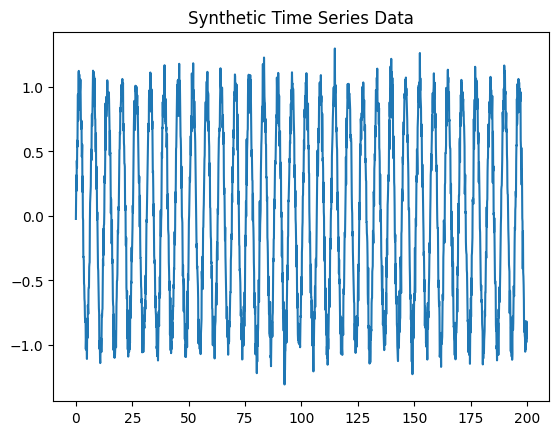

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - loss: 0.1188 - val_loss: 0.0322
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0267 - val_loss: 0.0243
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0200 - val_loss: 0.0158
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0069 - val_loss: 0.0019
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0019 - val_loss: 0.0020
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0018 - val_loss: 0.0018
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0018 - val_loss: 0.0018
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0018 - val_loss: 0.0019
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0019 - val_loss: 0.0018
Epoch 10/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0018 - val_loss: 0.0018


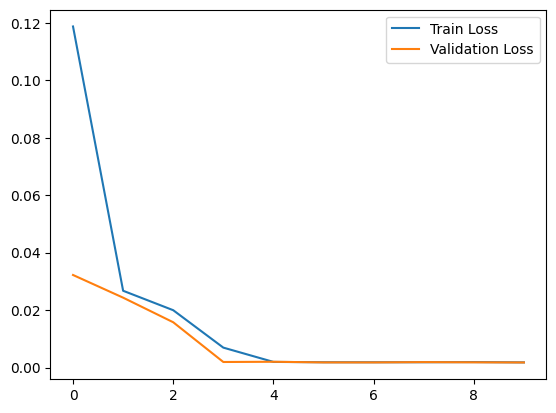

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


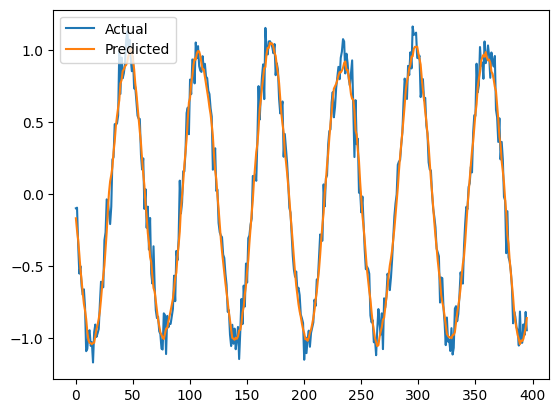

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# 1. Generate synthetic time series data
time = np.arange(0, 200, 0.1)
data = np.sin(time) + 0.1 * np.random.randn(len(time))
plt.plot(time, data)
plt.title("Synthetic Time Series Data")
plt.show()

# 2. Normalize the data
scaler = MinMaxScaler(feature_range=(0, 1))
data_scaled = scaler.fit_transform(data.reshape(-1, 1))

# 3. Create sequences (Fixed indentation error here)
def create_sequences(dataset, seq_length):
    X, y = [], []
    for i in range(len(dataset) - seq_length):
        X.append(dataset[i:i+seq_length, 0])
        y.append(dataset[i+seq_length, 0])
    return np.array(X), np.array(y)

SEQ_LEN = 20
X, y = create_sequences(data_scaled, SEQ_LEN)

# 4. Reshape for LSTM (samples, timesteps, features)
X = X.reshape((X.shape[0], X.shape[1], 1))

# 5. Train-test split
split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

# 6. Build LSTM model
model = Sequential([
    LSTM(50, activation='relu', input_shape=(SEQ_LEN, 1)),
    Dense(1)
])
model.compile(optimizer='adam', loss='mse')

# 7. Train model
history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_test, y_test), verbose=1)

# 8. Plot training loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.show()

# 9. Forecast
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(predictions.reshape(-1, 1))
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1))

# 10. Plot predictions vs actual
plt.plot(y_test_actual, label='Actual')
plt.plot(predictions, label='Predicted')
plt.legend()
plt.show()

In [4]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Embedding, GlobalAveragePooling1D, Dense
# 1. Load IMDB dataset (Movie Reviews)
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.imdb.load_data(
 num_words=10000
)
# 2. Make all reviews the same length
x_train = tf.keras.preprocessing.sequence.pad_sequences(
 x_train, maxlen=200
)
x_test = tf.keras.preprocessing.sequence.pad_sequences(
 x_test, maxlen=200
)
# 3. Create deep learning model
model = Sequential([
 Embedding(10000, 32),
 GlobalAveragePooling1D(),
 Dense(64, activation='relu'),
 Dense(1, activation='sigmoid')
])
# 4. Compile model
model.compile(
 optimizer='adam',
 loss='binary_crossentropy',
 metrics=['accuracy']
)
# 5. Train model
model.fit(
 x_train,
 y_train,
 epochs=5,
 batch_size=32,
 validation_split=0.2
)
# 6. Test model
loss, accuracy = model.evaluate(x_test, y_test)
print("Test Accuracy:", accuracy)
# 7. Predict first 5 reviews
predictions = model.predict(x_test[:5])
print("\nReview Classification:")
for i in range(5):
    if predictions[i][0] >= 0.5:
        result = "Positive"
    else:
        result = "Negative"
    print("Review", i + 1, ":", result)
    print("Probability:", predictions[i][0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7776 - loss: 0.4699 - val_accuracy: 0.8390 - val_loss: 0.3589
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8903 - loss: 0.2645 - val_accuracy: 0.8646 - val_loss: 0.3124
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.9179 - loss: 0.2115 - val_accuracy: 0.8636 - val_loss: 0.3257
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9344 - loss: 0.1752 - val_accuracy: 0.8776 - val_loss: 0.3137
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9466 - loss: 0.1477 - val_accuracy: 0.8524 - val_loss: 0.4007
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8448 - loss: 0.4195
Test Accuracy: 0.8447999954223633
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step

Review Classification:
Review 1 : Positive
Probability: 0.6949041
Review 2 : Positive
Probability: 0.99980426
Review 3 : Positive
Probability: 0.94654006
Review 4 :

In [5]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
# 1. Load CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
# Convert labels to 1D
y_train = y_train.flatten()
y_test = y_test.flatten()
# 2. Resize images
x_train = tf.image.resize(x_train, (96, 96))
x_test = tf.image.resize(x_test, (96, 96))
# 3. Load pre-trained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
 input_shape=(96, 96, 3),
 include_top=False,
 weights="imagenet"
)
# Freeze pre-trained layers
base_model.trainable = False
# 4. Create model
model = tf.keras.Sequential([
 base_model,
 tf.keras.layers.GlobalAveragePooling2D(),
 tf.keras.layers.Dense(64, activation="relu"),
 tf.keras.layers.Dense(10, activation="softmax")
])
# 5. Compile
model.compile(
 optimizer="adam",
 loss="sparse_categorical_crossentropy",
 metrics=["accuracy"]
)
# 6. Train
history = model.fit(
 x_train,
 y_train,
 epochs=5,
 batch_size=32,
 validation_split=0.2
)
# 7. Test model
loss, accuracy = model.evaluate(x_test, y_test)
print("Test Accuracy:", accuracy * 100, "%")
# 8. Predict one image
prediction = model.predict(x_test[:1])
classes = [
 "airplane", "automobile", "bird", "cat", "deer",
 "dog", "frog", "horse", "ship", "truck"
]
predicted_class = np.argmax(prediction)
print("Actual:", classes[y_test[0]])
print("Predicted:", classes[predicted_class])
# Print final training and validation accuracy
train_accuracy = history.history["accuracy"][-1]
val_accuracy = history.history["val_accuracy"][-1]
print("Training Accuracy:", train_accuracy * 100, "%")
print("Validation Accuracy:", val_accuracy * 100, "%")
# Test accuracy
loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print("Test Accuracy:", test_accuracy * 100, "%")
# Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(
 history.history["accuracy"],
 label="Training Accuracy"
)
plt.plot(
 history.history["val_accuracy"],
 label="Validation Accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2108s 12us/step
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 362s 285ms/step - accuracy: 0.4097 - loss: 1.6488 - val_accuracy: 0.4736 - val_loss: 1.5046
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 331s 264ms/step - accuracy: 0.4805 - loss: 1.4591 - val_accuracy: 0.4875 - val_loss: 1.4605
Epoch 3/5
1197/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 210ms/step - accuracy: 0.5036 - loss: 1.4025

KeyboardInterrupt: 

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
# Dataset
reviews = [
 "I loved this movie, it was fantastic",
 "The product is excellent and very useful",
 "Amazing experience, I really enjoyed it",
 "The service was wonderful",
 "Very happy with my purchase",
 "This product is terrible",
 "I hated this movie",
 "Very disappointing experience",
 "The product broke after one day",
 "Poor quality and bad service"
]
# Labels: 1 = Positive, 0 = Negative
labels = [
 1, 1, 1, 1, 1,
 0, 0, 0, 0, 0
]
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
 reviews,
 labels,
 test_size=0.2,
 random_state=42,
 stratify=labels
)
# Convert text into TF-IDF features
vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)
# Train the model
model = LogisticRegression()
model.fit(X_train_tfidf, y_train)
# Predict test data
y_pred = model.predict(X_test_tfidf)
# Test new reviews
new_reviews = [
 "The movie was amazing and I loved it",
 "The product was awful and disappointing",
 "I am very happy with this purchase"
]
new_reviews_tfidf = vectorizer.transform(new_reviews)
predictions = model.predict(new_reviews_tfidf)
# Display results
for review, prediction in zip(new_reviews, predictions):
 sentiment = "Positive" if prediction == 1 else "Negative"
 print("\nReview:", review)
 print("Sentiment:", sentiment)


Review: The movie was amazing and I loved it
Sentiment: Positive

Review: The product was awful and disappointing
Sentiment: Positive

Review: I am very happy with this purchase
Sentiment: Negative
